# Turtle Breakout 06 — protective put at the entry strike, and calls instead of the perpetual

Pre-registration: `discussions/Turtle_Breakout/008_claude_tb06_preregistration.md`. Code: `src/data_engineering/modeling/turtle_options.py`.

The daily turtle (TB 01 rules) on BTC and ETH. Option tenor: the first Friday 08:00 UTC at least **38 days** after entry (mean hold of the $R\ge3$ trades in the TB 04 discovery set).

| | strategy |
|---|---|
| S0 | perpetual (TB 01) |
| S1 | perpetual + put struck at the entry price, sold when the turtle exits (or settled at expiry) |
| S2 | call struck at the entry price instead of the perpetual, sold when the turtle exits, rolled at expiry |
| S3 | call struck one ATR above the entry |

Options priced with Black-76 at Deribit's DVOL (30-day ATM implied vol), bought at $\sigma(1+h)$ and sold at $\sigma(1-h)$, $h=2\%$; Deribit option fees. Results per trade in $R$ = 2 ATR at entry.

Environment: `TB01_DATA_DIR`, `TB06_SYNTHETIC=1`.

In [1]:
import os, sys, json, time, subprocess, tempfile, warnings
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_options as to, turtle_trade_features as tf

SYNTHETIC = os.getenv('TB06_SYNTHETIC', '0') == '1'
P = tb.Params(); O = to.OParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb06-')) / '06'; O = replace(O, n_boot=300)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '06'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    DVOL_DIR = Path(os.environ['DERIBIT_DATA_ROOT']) / 'history' / 'dvol'
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_options.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print(json.dumps(to.registration(O), indent=1))

OK
{
 "dte_days": 38,
 "half_spread": 0.02,
 "fee_rate": 0.0003,
 "fee_cap": 0.125,
 "delivery_rate": 0.00015,
 "otm_atr": 1.0,
 "n_boot": 2000,
 "block_days": 21,
 "alpha": 0.05,
 "seed": 20261029,
 "status": "PREREGISTERED_TB008",
 "version": "TB06-0.1.0",
 "assets": [
  "BTC",
  "ETH"
 ],
 "dte_source": "TB 04 discovery: mean hold of R>=3 trades = 37.8 d",
 "strategies": {
  "S0": "perp",
  "S1": "perp + put K=entry, sold at turtle exit or settled at expiry",
  "S2": "call K=entry, sold at turtle exit, rolled at expiry",
  "S3": "call K=entry+1 ATR"
 },
 "pricing": "Black-76, sigma = DVOL as of the bar; buy at sigma(1+h), sell at sigma(1-h)",
 "tests": {
  "Q1": "S1 vs S0",
  "Q2": "S2 vs S0",
  "alpha_each": 0.025,
  "stat": "paired Sharpe difference of daily cumulative-R curves (21d circular block bootstrap) -> IMPROVES (lower > 0) / WORSENS (upper < 0) / NO_DIFFERENCE; per-trade mean R difference (month-cluster bootstrap) and max drawdown reported"
 }
}


## 1. Data, turtle trades and option legs

In [2]:
T0 = time.time(); D, DV, TR = {}, {}, {}
for i, a in enumerate(to.ASSETS):
    if SYNTHETIC:
        b = tb.synthetic_5m(2100, seed=30 + i, trend=0.01, start='2020-09-01'); f = tb.synthetic_funding(b, 0.0001)
        dv = to.synthetic_dvol(pd.Timestamp('2021-03-24', tz='UTC'), b.index[-1], 0.6 + 0.1 * i)
    else:
        b = tb.bars_5m(pd.read_parquet(DATA / f'{a}USDT_um_1m.parquet', columns=['open_time', 'open', 'high', 'low', 'close']))
        f = tb.funding_events(pd.read_parquet(DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'))
        dv = to.load_dvol(DVOL_DIR / f'{a}_dvol_1h.csv')
    D[a] = tb.prepare_asset(a, b, f, P); DV[a] = dv
    START = max(tb.COMMON_START, dv.index[0] + pd.Timedelta(days=2))
    TR[a] = tf.run_trades(D[a], P, START)
    print(a, 'DVOL', dv.index[0].date(), '->', dv.index[-1].date(), '| trades from', START.date(), ':', len(TR[a]))
END = min(d.end[-1] for d in D.values())
X = {h: pd.concat([to.run_asset(D[a], DV[a], TR[a], O, h) for a in to.ASSETS], ignore_index=True) for h in (O.half_spread, 0.0, 0.05)}
XP = X[O.half_spread]
print(f'{len(XP)} trades, {time.time() - T0:.0f}s'); display(XP.head(3))

BTC DVOL 2021-03-24 -> 2026-10-25 | trades from 2021-03-26 : 45
ETH DVOL 2021-03-24 -> 2026-10-25 | trades from 2021-03-26 : 41
86 trades, 4s


,asset,entry_time,exit_time,entry_px,exit_px,atr_entry,perp_R,reason,put_R,put_premium_R,put_how,put_hold_R,callATM_noroll_R,callATM_R,callATM_legs,callATM_premium_R,callOTM_noroll_R,callOTM_R,callOTM_legs,callOTM_premium_R,sigma_entry,perp_put_R,perp_put_hold_R
0,BTC,2021-04-10 04:20:00+00:00,2021-04-18 03:25:00+00:00,60397.85,55759.13,3035.220350,-1.013712,trail,0.216399,1.047067,sold,2.338473,-0.504708,-0.504708,1,1.066856,-0.445076,-0.445076,1,0.860055,0.7790,-0.797312,1.324762
1,BTC,2021-05-10 04:10:00+00:00,2021-05-12 22:10:00+00:00,59590.96,52880.38,3420.927118,-1.023735,trail,0.408618,1.025267,sold,2.172333,-0.512476,-0.512476,1,0.987070,-0.438424,-0.438424,1,0.787782,0.8716,-0.615117,1.148599
2,BTC,2021-06-14 14:20:00+00:00,2021-06-20 10:10:00+00:00,40900.00,34585.90,3798.205074,-0.842940,trail,0.333550,0.726106,sold,0.380295,-0.516893,-0.516893,1,0.724763,-0.413764,-0.413764,1,0.534164,1.0214,-0.509391,-0.462646


## 2. Per-trade results (R)

In [3]:
COLS = {'S0 perp': 'perp_R', 'S1 perp + put (entry strike)': 'perp_put_R', 'S1b perp + put held to expiry': 'perp_put_hold_R',
        'S2 call ATM (rolled)': 'callATM_R', 'S2b call ATM (no roll)': 'callATM_noroll_R', 'S3 call +1 ATR (rolled)': 'callOTM_R',
        'S3b call +1 ATR (no roll)': 'callOTM_noroll_R'}
def per_trade(Xh):
    return pd.DataFrame({k: {'trades': len(Xh), 'win_rate': float((Xh[c] > 0).mean()), 'mean_R': float(Xh[c].mean()), 'median_R': float(Xh[c].median()),
                             'sum_R': float(Xh[c].sum()), 'worst_R': float(Xh[c].min()), 'best_R': float(Xh[c].max()),
                             'R_from_top5': float(Xh[c].nlargest(5).sum())} for k, c in COLS.items()}).T
PT = per_trade(XP); display(PT.round(3))
print('Put leg alone: mean premium', round(XP.put_premium_R.mean(), 3), 'R; mean put P&L', round(XP.put_R.mean(), 3), 'R; pays (>0) on',
      f"{(XP.put_R > 0).mean():.0%} of trades; expired before the turtle exit on {(XP.put_how == 'expired').mean():.0%}")
print('Call ATM: mean first premium', round(XP.callATM_premium_R.mean(), 3), 'R; trades needing a roll', f"{(XP.callATM_legs > 1).mean():.0%}")
SENS = pd.concat({f'h={h:.0%}': per_trade(Xh)[['mean_R', 'sum_R']] for h, Xh in X.items()}, axis=1); print('Spread sensitivity'); display(SENS.round(3))
bins = pd.cut(XP.perp_R, [-np.inf, -0.5, 0, 1, 3, np.inf])
display(XP.groupby(bins, observed=True)[['perp_R', 'put_R', 'perp_put_R', 'callATM_R', 'callOTM_R']].agg(['count', 'mean']).round(3))

,trades,win_rate,mean_R,median_R,sum_R,worst_R,best_R,R_from_top5
S0 perp,86.0,0.395,0.470,-0.355,40.435,-1.088,9.255,33.784
S1 perp + put (entry strike),86.0,0.302,0.282,-0.406,24.236,-0.890,8.411,28.513
S1b perp + put held to expiry,86.0,0.442,0.218,-0.261,18.744,-2.405,8.411,28.513
S2 call ATM (rolled),86.0,0.302,0.350,-0.407,30.116,-0.827,6.702,29.662
S2b call ATM (no roll),86.0,0.302,0.375,-0.407,32.255,-0.827,6.488,29.497
S3 call +1 ATR (rolled),86.0,0.291,0.316,-0.360,27.207,-0.744,6.252,28.142
S3b call +1 ATR (no roll),86.0,0.291,0.341,-0.360,29.357,-0.744,6.209,28.133


Put leg alone: mean premium 1.004 R; mean put P&L -0.188 R; pays (>0) on 47% of trades; expired before the turtle exit on 7%
Call ATM: mean first premium 1.036 R; trades needing a roll 7%
Spread sensitivity


h=2%           h=0%           h=5%        
                              mean_R   sum_R mean_R   sum_R mean_R   sum_R
S0 perp                        0.470  40.435  0.470  40.435  0.470  40.435
S1 perp + put (entry strike)   0.282  24.236  0.314  26.963  0.234  20.154
S1b perp + put held to expiry  0.218  18.744  0.238  20.455  0.188  16.179
S2 call ATM (rolled)           0.350  30.116  0.386  33.159  0.297  25.562
S2b call ATM (no roll)         0.375  32.255  0.407  34.984  0.328  28.171
S3 call +1 ATR (rolled)        0.316  27.207  0.351  30.227  0.264  22.690
S3b call +1 ATR (no roll)      0.341  29.357  0.373  32.063  0.294  25.311

perp_R        put_R        perp_put_R        callATM_R        callOTM_R       
              count   mean count   mean      count   mean     count   mean     count   mean
perp_R                                                                                     
(-inf, -0.5]     37 -0.939    37  0.358         37 -0.581        37 -0.571        37 -0.493
(-0.5, 0.0]      15 -0.309    15 -0.160         15 -0.468        15 -0.450        15 -0.415
(0.0, 1.0]       11  0.386    11 -0.489         11 -0.103        11 -0.065        11 -0.114
(1.0, 3.0]       14  1.870    14 -0.871         14  0.999        14  1.275        14  1.044
(3.0, inf]        9  5.486     9 -1.053          9  4.433         9  4.540         9  4.259

## 3. Pre-registered comparisons on daily cumulative-R curves (BTC + ETH)

In [4]:
START = max(pd.Timestamp(XP.entry_time.min()), tb.COMMON_START)
days = to.daily_days(START, END)
CURVE = {k: sum(to.daily_curve(D[a], DV[a], XP[XP.asset == a], k, O, O.half_spread, days) for a in to.ASSETS)
         for k in ('perp', 'perp_put', 'callATM', 'callOTM')}
q = O.alpha / 2
Q = {'Q1 S1 perp+put vs S0 perp': to.sharpe_diff_R(CURVE['perp_put'], CURVE['perp'], O, q, O.seed + 1),
     'Q2 S2 call ATM vs S0 perp': to.sharpe_diff_R(CURVE['callATM'], CURVE['perp'], O, q, O.seed + 2),
     'S3 call +1 ATR vs S0 (reported)': to.sharpe_diff_R(CURVE['callOTM'], CURVE['perp'], O, q, O.seed + 3)}
display(pd.DataFrame(Q).T.round(3))
MD = {'Q1 per-trade mean R, S1 - S0': to.mean_diff_month(XP.perp_put_R.to_numpy(), XP.perp_R.to_numpy(), pd.DatetimeIndex(XP.entry_time), O, q, O.seed + 4),
      'Q2 per-trade mean R, S2 - S0': to.mean_diff_month(XP.callATM_R.to_numpy(), XP.perp_R.to_numpy(), pd.DatetimeIndex(XP.entry_time), O, q, O.seed + 5)}
display(pd.DataFrame(MD).T.round(3))
CUR = pd.DataFrame({k: {'total_R': float(c.iloc[-1]), 'max_drawdown_R': to.max_dd(c), 'sharpe_daily': float(c.diff().mean() / c.diff().std() * np.sqrt(365))} for k, c in CURVE.items()}).T
display(CUR.round(3))
DECISION = {'Q1_put_hedge': Q['Q1 S1 perp+put vs S0 perp']['result'], 'Q2_call_only': Q['Q2 S2 call ATM vs S0 perp']['result'],
            'trades': len(XP), 'window': [str(START), str(END)]}
print(json.dumps(DECISION, indent=1))

,sharpe_a,sharpe_b,diff,lo,hi,ci_level,days,result
Q1 S1 perp+put vs S0 perp,0.53447,0.761058,-0.226588,-0.41288,-0.05008,0.975,2032,WORSENS
Q2 S2 call ATM vs S0 perp,0.677944,0.761058,-0.083114,-0.360947,0.199187,0.975,2032,NO_DIFFERENCE
S3 call +1 ATR vs S0 (reported),0.637363,0.761058,-0.123695,-0.454803,0.211326,0.975,2032,NO_DIFFERENCE


,mean_diff_R,lo,hi,trades
"Q1 per-trade mean R, S1 - S0",-0.188,-0.343,-0.023,86.0
"Q2 per-trade mean R, S2 - S0",-0.120,-0.301,0.049,86.0


,total_R,max_drawdown_R,sharpe_daily
perp,40.435,-10.284,0.761
perp_put,24.236,-9.906,0.534
callATM,30.116,-10.551,0.678
callOTM,27.207,-10.517,0.637


{
 "Q1_put_hedge": "WORSENS",
 "Q2_call_only": "NO_DIFFERENCE",
 "trades": 86,
 "window": [
  "2021-03-31 21:25:00+00:00",
  "2026-10-24 00:00:00+00:00"
 ]
}


## 4. Years

In [5]:
yr = pd.to_datetime(XP.exit_time).dt.year
YR = XP.groupby(yr)[['perp_R', 'perp_put_R', 'callATM_R', 'callOTM_R']].sum().assign(trades=XP.groupby(yr).size())
display(YR.round(2))

,perp_R,perp_put_R,callATM_R,callOTM_R,trades
exit_time,,,,,
2021,2.37,-0.19,3.46,2.81,12
2022,-4.01,-3.98,-4.35,-4.08,14
2023,17.19,12.21,11.21,10.23,13
2024,16.45,12.73,14.97,14.25,20
2025,1.96,1.33,2.26,1.85,14
2026,6.47,2.13,2.58,2.15,13


## 5. Figures

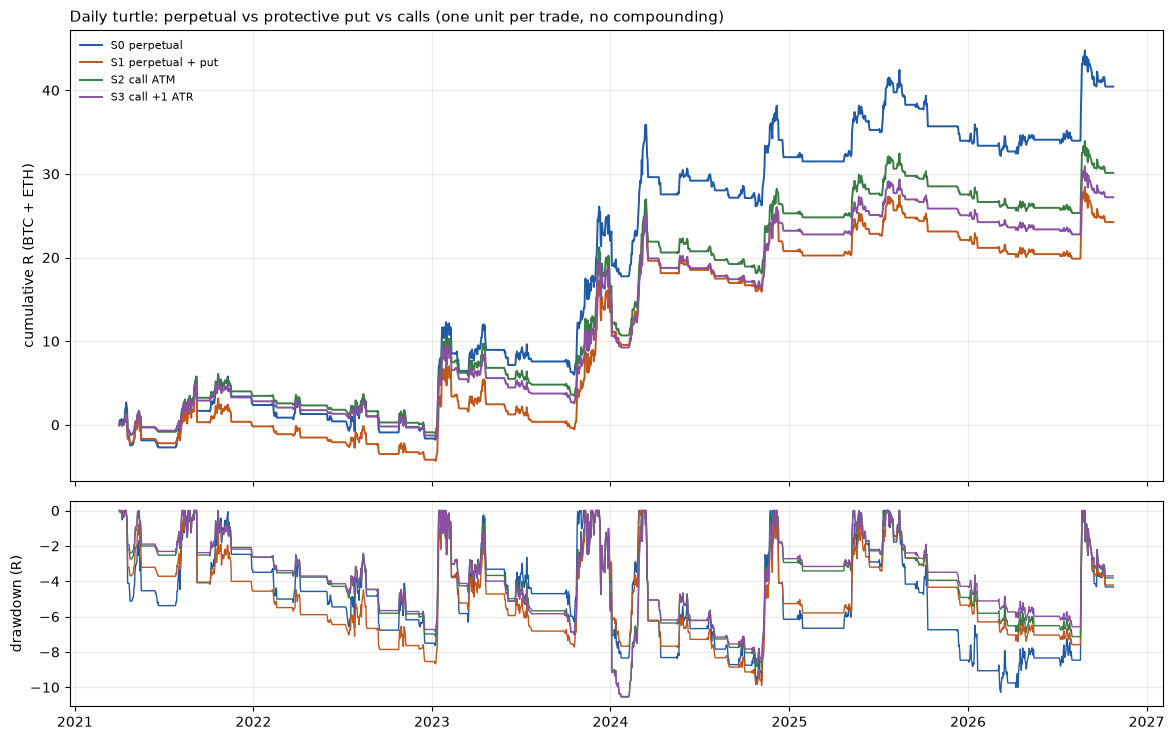

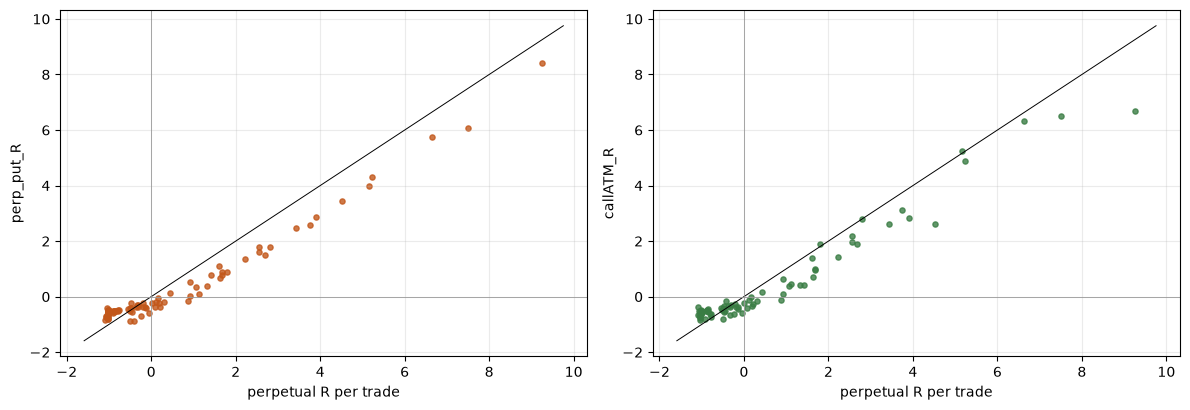

In [6]:
cols = {'perp': ('#1f5aa6', 'S0 perpetual'), 'perp_put': ('#c2571a', 'S1 perpetual + put'), 'callATM': ('#3a7d44', 'S2 call ATM'), 'callOTM': ('#8a4fa3', 'S3 call +1 ATR')}
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
for k, (c, lab) in cols.items():
    axes[0].plot(CURVE[k].index, CURVE[k], color=c, lw=1.4, label=lab); axes[1].plot(CURVE[k].index, CURVE[k] - CURVE[k].cummax(), color=c, lw=1)
axes[0].set_ylabel('cumulative R (BTC + ETH)'); axes[0].legend(frameon=False, fontsize=8); axes[1].set_ylabel('drawdown (R)')
axes[0].set_title('Daily turtle: perpetual vs protective put vs calls (one unit per trade, no compounding)', loc='left', fontsize=11)
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, k, c in ((axes[0], 'perp_put_R', '#c2571a'), (axes[1], 'callATM_R', '#3a7d44')):
    ax.scatter(XP.perp_R, XP[k], s=14, color=c, alpha=0.8); lim = [XP.perp_R.min() - 0.5, XP.perp_R.max() + 0.5]
    ax.plot(lim, lim, color='k', lw=0.7); ax.axhline(0, color='0.6', lw=0.6); ax.axvline(0, color='0.6', lw=0.6)
    ax.set_xlabel('perpetual R per trade'); ax.set_ylabel(k); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Exports

In [7]:
XP.to_csv(OUT / '06_trades.csv', index=False, float_format='%.6g'); PT.to_csv(OUT / '06_per_trade.csv', float_format='%.6g')
SENS.to_csv(OUT / '06_spread_sensitivity.csv', float_format='%.6g'); CUR.to_csv(OUT / '06_curves_summary.csv', float_format='%.6g')
pd.DataFrame(CURVE).to_csv(OUT / '06_curves_daily.csv', float_format='%.5g'); YR.to_csv(OUT / '06_years.csv', float_format='%.6g')
pd.DataFrame({**Q, **MD}).T.to_csv(OUT / '06_tests.csv', float_format='%.6g')
(OUT / '06_decision.json').write_text(json.dumps({'decision': DECISION, 'tests': {**Q, **MD}, 'registration': to.registration(O)}, indent=1, default=float))
(OUT / '06_manifest.json').write_text(json.dumps({'module': 'Turtle_Breakout_06', 'version': to.VERSION, 'synthetic': SYNTHETIC,
    'runtime_s': round(time.time() - T0, 1)}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['06_curves_daily.csv', '06_curves_summary.csv', '06_decision.json', '06_manifest.json', '06_per_trade.csv', '06_spread_sensitivity.csv', '06_tests.csv', '06_trades.csv', '06_years.csv']
